In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import janitor

pd.set_option('display.max_columns', None)

file = '/Users/jonzimmerman/Desktop/Data Projects/ABS Challenge/data/challenge_data_2026_reg.csv'
df = pd.read_csv(file).clean_names()
print(df.shape)

(10557, 30)


In [2]:
df.head(2)

,play_id,date,player,role,team,opp,team_score,opp_score,inn,balls,strikes,outs,runners,challenges_remaining,call,result,net_re,net_wpa,dist_in_,xchall%,call_li,cbe%,acbe%,xstr%,opp_cost_re,opp_cost_wpa,potential_run_expectancy_delta_if_overturned,potential_win_probability_added_if_overturned,runs_over_expected,wins_over_expected
0,2ff576ef-65e7-380a-be70-d68eae4c7501,2026-09-27,Brady House,batter,WSH,NYM,3,4,3,2,1,0,Empty,2,Called Strike,True,0.1760,0.020800,-2.39,0.366641,1.37,0.5064,0.0000,0.070886,0.0000,0.000000,0.176,0.0208,0.111471,0.013174
1,e488118c-2162-35be-809f-055cb4feb9cf,2026-09-27,Marcus Semien,batter,NYM,WSH,4,2,3,0,0,1,1B,1,Called Strike,False,-0.1101,-0.009716,2.27,0.012606,0.44,0.6686,0.5511,0.932469,0.1101,0.009716,0.090,0.0067,-0.108712,-0.009594


### Glossary

- **Net RE**: Net run expectancy impact. Potential RE delta if overturned, or negative opportunity cost if upheld
- **Net win probability impact**: Potential WPA delta if overturned, or negative opportunity cost (WPA) if upheld
- **Dist (in)**: Signed distance from the ball's edge to the nearest zone edge at midplate, in inches
- **xChall%**: Model-predicted probability that a given pitch would be challenged
- **Call LI**: Leverage of the pitch, limited to the ball/strike outcome. 1.0 = average; 2.0 = twice as impactful
- **cBE%**: Unadjusted challenge breakeven %. The minimum probability of overturn needed to justify a challenge, based on the run expectancy swing for this count/base-out state. Does not account for opportunity cost or game timing
- **acBE%**: Breakeven threshold adjusted for opportunity cost and game timing
- **xStr%**: Model-predicted probability the pitch would be called a strike by an average umpire
- **Opp Cost RE**: Expected RE lost from using a challenge here, accounting for the cost of future opportunities
- **Opp Cost WPA**: Expected win probability lost from using a challenge here, sensitive to score and inning
- **pRE**: Potential run expectancy delta if overturned
- **pWPA**: Potential win probability added if overturned
- **ROE**: Runs over expected
- **WOE**: Wins over expected

In [3]:
conditions = [
    (df['call'] == "Called Strike") & df['result'],
    (df['call'] == "Called Strike") & ~df['result'],
    (df['call'] == "Ball") & df['result'],
    (df['call'] == "Ball") & ~df['result'],
]

choices = [
    "Ball",
    "Strike",
    "Strike",
    "Ball",
]

df['updated_call'] = np.select(conditions, choices, default=df['call'])
col = df.pop('updated_call')
df.insert(15, 'updated_call', col)

In [4]:
al = ['ATH', 'BAL', 'BOS', 'CWS', 'CLE', 
      'DET', 'HOU', 'KC',  'LAA', 'MIN', 
      'NYY', 'SEA', 'TEX', 'TOR', 'TB'
] 

nl = ['AZ',  'ATL', 'CHC', 'CIN', 'COL', 
      'LAD', 'MIA', 'MIL', 'NYM', 'PHI', 
      'PIT', 'SD',  'SF',  'STL', 'WSH'
]

league_map = {t: 'AL' for t in al} | {t: 'NL' for t in nl}

df['league'] = df['team'].map(league_map)
league_colors = {'AL': 'crimson', 'NL': 'royalblue'}


### Challenge EDA

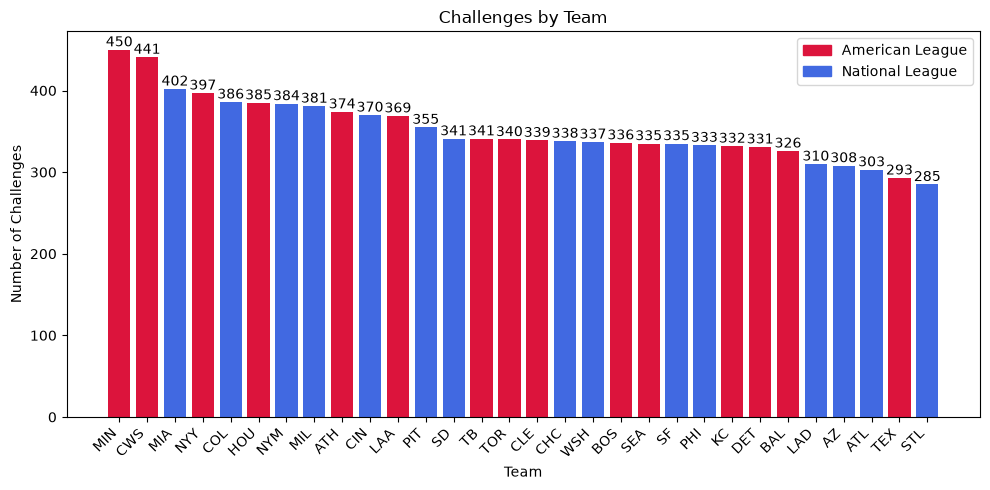

In [5]:
total_counts = df['team'].value_counts()
colors = [league_colors[league_map[t]] for t in total_counts.index]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(total_counts.index, total_counts.values, color=colors)
ax.bar_label(ax.containers[0])
ax.set_title('Challenges by Team')
ax.set_xlabel('Team')
ax.set_ylabel('Number of Challenges')
ax.legend(handles=[Patch(color='crimson', label='American League'),
                   Patch(color='royalblue', label='National League')])
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

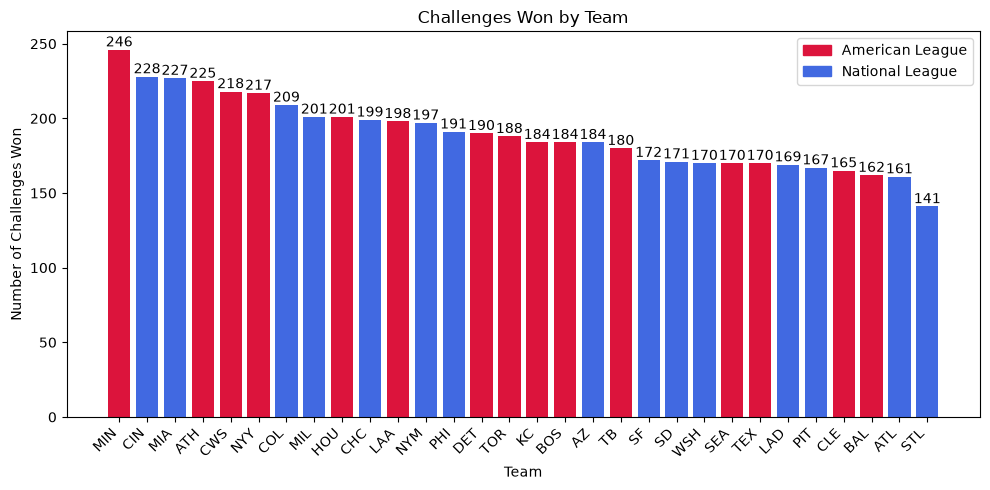

In [6]:
challenge1 = df[['team','result']]
challenge1 = challenge1[challenge1['result']==True]['team'].value_counts()
colors = [league_colors[league_map[t]] for t in challenge1.index]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(challenge1.index, challenge1.values, color=colors)

ax.bar_label(ax.containers[0])
ax.set_title('Challenges Won by Team')
ax.set_xlabel('Team')
ax.set_ylabel('Number of Challenges Won')
ax.legend(handles=[Patch(color='crimson', label='American League'),
                   Patch(color='royalblue', label='National League')])
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

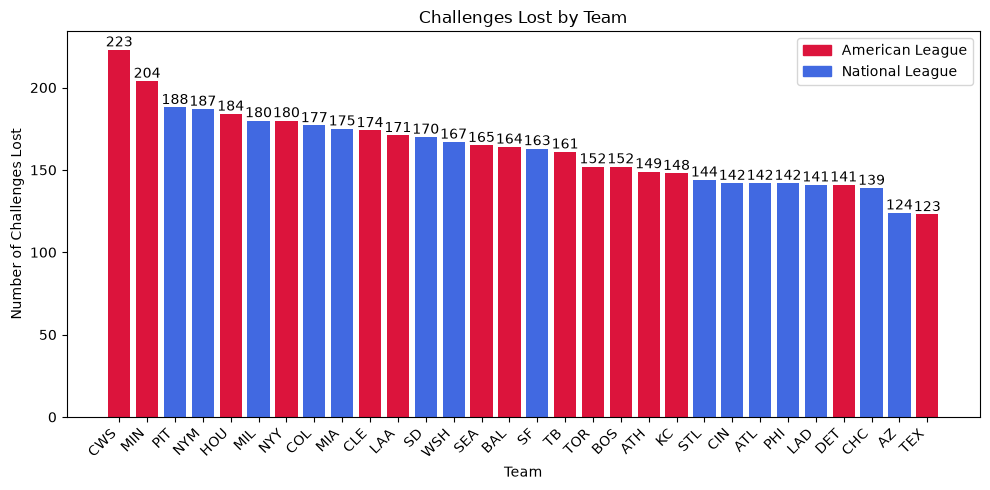

In [7]:
challenge2 = df[['team','result']]
challenge2 = challenge2[challenge2['result']==False]['team'].value_counts()
colors = [league_colors[league_map[t]] for t in challenge2.index]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(challenge2.index, challenge2.values, color=colors)
ax.bar_label(ax.containers[0])
ax.set_title('Challenges Lost by Team')
ax.set_xlabel('Team')
ax.set_ylabel('Number of Challenges Lost')
ax.legend(handles=[Patch(color='crimson', label='American League'),
                   Patch(color='royalblue', label='National League')])
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [8]:
challenge = df[['team','result']].value_counts().reset_index()
table = challenge.pivot(index='team', columns='result', values='count').fillna(0).astype(int)
table = table.rename(columns={True: 'wins', False: 'losses'})
table['total'] = table['wins'] + table['losses']
table['win_pct'] = (table['wins'] / table['total'] * 100).round(1)
table.sort_values(by = 'win_pct', ascending = False).head()

result,losses,wins,total,win_pct
team,,,,
CIN,142,228,370,61.6
ATH,149,225,374,60.2
AZ,124,184,308,59.7
CHC,139,199,338,58.9
TEX,123,170,293,58.0


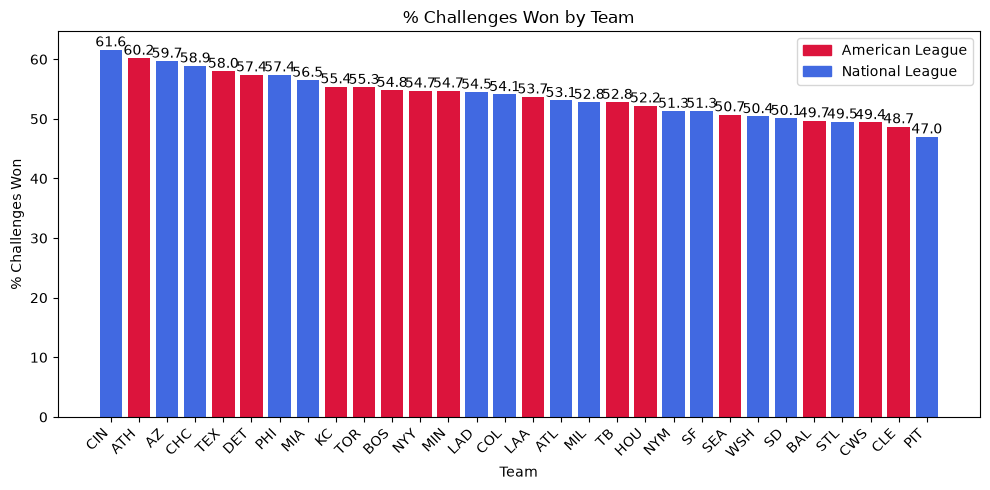

In [9]:
win_table = table.reset_index().sort_values('win_pct', ascending=False)
win_table['league'] = win_table['team'].map(league_map)
win_pct = win_table[['team', 'league', 'win_pct']]

colors = win_pct['team'].map(league_map).map(league_colors)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(win_pct['team'], win_pct['win_pct'], color=colors)
ax.bar_label(ax.containers[0], fmt='%.1f')
ax.set_title('% Challenges Won by Team')
ax.set_xlabel('Team')
ax.set_ylabel('% Challenges Won')
ax.legend(handles=[Patch(color='crimson', label='American League'),
                   Patch(color='royalblue', label='National League')])
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


### Who's the best challenger?

In [10]:
pos_challenge = df[['role','result']].value_counts().reset_index()
pos_table = pos_challenge.pivot(index='role', columns='result', values='count').fillna(0).astype(int)
pos_table = pos_table.rename(columns={True: 'wins', False: 'losses'})
pos_table['total'] = pos_table['wins'] + pos_table['losses']
pos_table['win_pct'] = (pos_table['wins'] / pos_table['total'] * 100).round(1)
pos_table.sort_values(by = 'win_pct', ascending=False)

result,losses,wins,total,win_pct
role,,,,
catcher,2326,3286,5612,58.6
batter,2438,2327,4765,48.8
pitcher,108,72,180,40.0


In [11]:
def challenge_result_table(challenger, filter_level):

    position = df[df['role']==challenger]
    challenge = position[['player','result']].value_counts().reset_index()
    table = challenge.pivot(index='player', columns='result', values='count').fillna(0).astype(int)
    table = table.rename(columns={True: 'wins', False: 'losses'})
    table['total'] = table['wins'] + table['losses']
    table['win_pct'] = (table['wins'] / table['total'] * 100).round(1)

    team_lookup = position.sort_values('date').groupby('player')['team'].last()
    table.insert(0, 'team', table.index.map(team_lookup))

    table = table[table['total']>=filter_level].sort_values(by = 'win_pct', ascending = False)

    return table


In [12]:
challenge_result_table('batter', 10)

result,team,losses,wins,total,win_pct
player,,,,,
CJ Abrams,WSH,2,12,14,85.7
Cedric Mullins,TB,2,11,13,84.6
Davis Schneider,TOR,3,14,17,82.4
Nick Kurtz,ATH,2,9,11,81.8
Zack Gelof,ATH,4,11,15,73.3
...,...,...,...,...,...
Nasim Nuñez,WSH,9,3,12,25.0
Ceddanne Rafaela,BOS,18,6,24,25.0
Justin Crawford,PHI,10,3,13,23.1


In [13]:
challenge_result_table('catcher', 10)

result,team,losses,wins,total,win_pct
player,,,,,
Adrian Del Castillo,AZ,1,9,10,90.0
P.J. Higgins,CIN,2,9,11,81.8
J.T. Realmuto,PHI,16,70,86,81.4
Sandy León,ATL,5,16,21,76.2
Mitch Garver,SEA,9,25,34,73.5
...,...,...,...,...,...
Yohel Pozo,BAL,8,6,14,42.9
Ali Sánchez,NYY,26,19,45,42.2
Endy Rodríguez,PIT,13,9,22,40.9


In [14]:
challenge_result_table('pitcher', 5)

result,team,losses,wins,total,win_pct
player,,,,,
Drew Anderson,DET,3,5,8,62.5
Freddy Peralta,TB,4,4,8,50.0
Hogan Harris,ATH,3,2,5,40.0
Shane Baz,BAL,3,2,5,40.0
Gregory Soto,PIT,4,2,6,33.3
George Kirby,SEA,4,1,5,20.0
Cristopher Sánchez,PHI,5,0,5,0.0


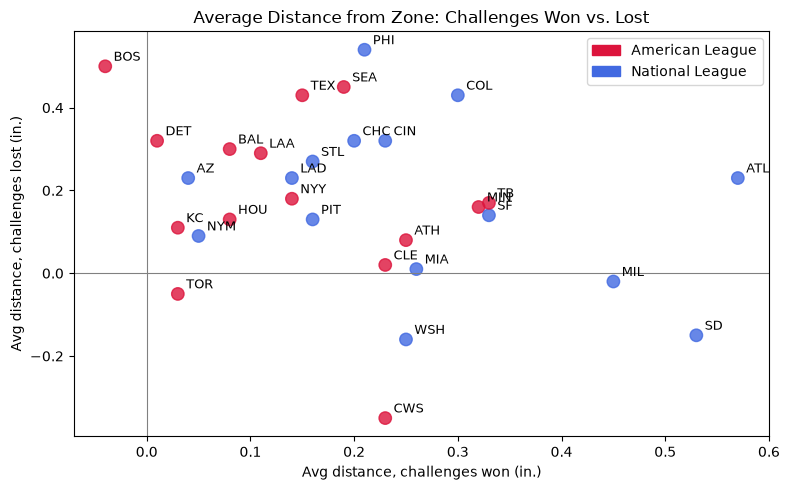

In [15]:
team_distance = df.pivot_table(index='team', columns='result', values='dist_in_', aggfunc='mean').round(2)
team_distance = team_distance.rename(columns={False: 'avg_dist_lost', True: 'avg_dist_won'})
team_distance['total'] = df.groupby('team').size()
team_distance = team_distance[team_distance['total'] >= 10].reset_index()

league_colors = {'AL': 'crimson', 'NL': 'royalblue'}
colors = team_distance['team'].map(league_map).map(league_colors)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(team_distance['avg_dist_won'], team_distance['avg_dist_lost'],
           c=colors, s=80, alpha=0.8)

for _, row in team_distance.iterrows():
    ax.annotate(row['team'], (row['avg_dist_won'], row['avg_dist_lost']),
                textcoords='offset points', xytext=(6, 4), fontsize=9)

ax.axhline(0, color='gray', lw=0.8)
ax.axvline(0, color='gray', lw=0.8)

ax.set_title('Average Distance from Zone: Challenges Won vs. Lost')
ax.set_xlabel('Avg distance, challenges won (in.)')
ax.set_ylabel('Avg distance, challenges lost (in.)')
ax.legend(handles=[Patch(color='crimson', label='American League'),
                   Patch(color='royalblue', label='National League')])
plt.tight_layout()
plt.show()

In [16]:
def how_close(role_filter, filter_level, balls=False, strikes=False):
    data = df[df['role'] == role_filter]

    if balls and not strikes:
        data = data[data['dist_in_'] < 0]
    elif strikes and not balls:
        data = data[data['dist_in_'] > 0]

    table = data.pivot_table(index='player', columns='result', values='dist_in_', aggfunc='mean').round(2)
    table = table.rename(columns={False: 'avg_dist_lost', True: 'avg_dist_won'})
    table['total'] = data.groupby('player').size()
    table = table[table['total'] >= filter_level]

    table = table.dropna(axis=1, how='all')

    dist_cols = [c for c in table.columns if c.startswith('avg_dist')]
    table = table.loc[table[dist_cols].abs().mean(axis=1).sort_values().index]

    team_lookup = data.sort_values('date').groupby('player')['team'].last()
    table.insert(0, 'team', table.index.map(team_lookup))

    return table.reset_index()

In [17]:
how_close('catcher', 10, balls=True) 

result,player,team,avg_dist_lost,total
0,J.T. Realmuto,PHI,-0.43,16
1,Jake Rogers,CWS,-0.69,19
2,Victor Caratini,MIN,-0.71,51
3,Endy Rodríguez,PIT,-0.75,13
4,James McCann,AZ,-0.76,28
...,...,...,...,...
68,Edgar Quero,CWS,-1.42,47
69,Liam Hicks,TB,-1.43,38
70,Alejandro Kirk,TOR,-1.47,37
71,Freddy Fermin,SD,-1.50,45


In [18]:
how_close('catcher', 10, strikes=True) 

result,player,team,avg_dist_won,total
0,Eric Haase,SF,0.84,12
1,Agustín Ramírez,MIA,0.94,28
2,Brian Navarreto,MIA,0.96,14
3,Jhonny Pereda,SEA,0.98,19
4,Moisés Ballesteros,LAA,1.00,22
...,...,...,...,...
75,Will Smith,LAD,1.59,36
76,Francisco Alvarez,NYM,1.61,42
77,Jake Rogers,CWS,1.63,19
78,Travis d'Arnaud,LAA,1.68,11


In [19]:
how_close('batter', 10, strikes=True) 

result,player,team,avg_dist_lost,total
0,Taylor Walls,TB,0.82,10
1,Kevin McGonigle,DET,0.88,12
2,Willy Adames,SF,0.88,10
3,Travis Bazzana,CLE,0.90,10
4,Miguel Vargas,CWS,0.91,10
...,...,...,...,...
64,Jazz Chisholm Jr.,NYY,2.05,14
65,Junior Caminero,TB,2.05,15
66,José Fermín,STL,2.10,11
67,Samuel Basallo,BAL,2.39,10


In [20]:
how_close('batter', 10, balls=True) 

result,player,team,avg_dist_won,total
0,Heliot Ramos,NYY,-0.86,10
1,Randy Arozarena,SEA,-0.93,11
2,Cole Carrigg,COL,-0.93,12
3,Wyatt Langford,TEX,-0.93,10
4,Pete Crow-Armstrong,CHC,-0.98,10
...,...,...,...,...
64,Miguel Vargas,CWS,-1.81,13
65,Cedric Mullins,TB,-1.85,11
66,Zach Neto,LAA,-1.87,18
67,Kyle Karros,COL,-1.94,11
